# ShopSense: Online Retail EDA and data-quality audit

## Objective and scope
This notebook answers: what is the observed transaction volume and date coverage; how much data is missing or duplicated; how do cancellation invoices, returns, quantities, and prices behave; and how do explicit cleaning rules affect the usable transaction counts? Findings below are calculated from the local UCI Online Retail workbook, not hard-coded.

Run the notebook from the repository root, top to bottom. Download the **Online Retail** Excel workbook from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail) and place it at `data/raw/Online Retail.xlsx`. If it is absent, loading raises a clear file error; no replacement data is fabricated. The original workbook is read-only; generated CSV and JSON files are saved under the Git-ignored `data/processed/` directory.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Resolve the repository independently of whether Jupyter starts at the root.
project_root = next(
    (candidate for candidate in [Path.cwd(), *Path.cwd().parents]
     if (candidate / "src" / "preprocessing.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the ShopSense repository root.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import audit_transactions, clean_transactions, load_transactions, write_cleaning_outputs

raw_path = project_root / "data" / "raw" / "Online Retail.xlsx"
processed_path = project_root / "data" / "processed"
figures_path = project_root / "reports" / "figures"
figures_path.mkdir(parents=True, exist_ok=True)
print(f"Project root: {project_root}")
print(f"Raw data: {raw_path}")

Project root: C:\Users\krish\dev\02-projects\ml-project\ShopSense
Raw data: C:\Users\krish\dev\02-projects\ml-project\ShopSense\data\raw\Online Retail.xlsx


## Dataset source and loading

The source is an Excel transaction workbook, not a database. The loader validates all eight required transaction fields and normalizes `InvoiceDate`; a missing workbook, invalid Excel file, or missing required column is an explicit error.

In [2]:
transactions = load_transactions(raw_path)
print(f"Rows: {len(transactions):,}; columns: {transactions.shape[1]}")
print("Column names:", transactions.columns.tolist())
display(transactions.head())
display(transactions.dtypes.astype(str).rename("dtype").to_frame())

Rows: 541,909; columns: 8
Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


## Column meanings and actual date coverage

`InvoiceNo` identifies an invoice (a leading `C` is the documented cancellation convention); `StockCode` and `Description` identify a product; `Quantity` and `UnitPrice` describe a line; `InvoiceDate` is the transaction timestamp; `CustomerID` identifies a customer when present; `Country` is the invoice country. The date bounds below are calculated from parseable dates in this workbook.

In [3]:
date_audit = audit_transactions(transactions)
print("Parsed InvoiceDate dtype:", transactions["InvoiceDate"].dtype)
print("Invalid or missing dates:", f"{date_audit['invalid_or_missing_date_count']:,}")
print("Observed date coverage:", date_audit["date_coverage"])
print("These are observed dataset boundaries, not chosen modeling windows.")

Parsed InvoiceDate dtype: datetime64[ns]
Invalid or missing dates: 0
Observed date coverage: {'start': '2010-12-01T08:26:00', 'end': '2011-12-09T12:50:00'}
These are observed dataset boundaries, not chosen modeling windows.


## Missing values and exact duplicate rows

Missing-value percentages use all source rows as the denominator. Exact duplicates are compared across the original complete rows before any cleaning; these quality categories can overlap.

In [4]:
missing_table = pd.DataFrame(date_audit["missing_values"]).T
missing_table = missing_table.sort_values("count", ascending=False)
display(missing_table)
print("Exact duplicate rows:", f"{date_audit['exact_duplicate_row_count']:,}")
print("Missing values, duplicates, and other issue counts may overlap.")

,count,percentage
CustomerID,135080.0,24.926694
Description,1454.0,0.268311
StockCode,0.0,0.000000
InvoiceNo,0.0,0.000000
Quantity,0.0,0.000000
InvoiceDate,0.0,0.000000
UnitPrice,0.0,0.000000
Country,0.0,0.000000


Exact duplicate rows: 5,268
Missing values, duplicates, and other issue counts may overlap.


## Cancellation, return, quantity, and price checks

Invoice cancellation markers and negative quantities are audited separately: a negative quantity may be a return or correction, and is preserved in the general cleaned dataset. Zero and negative values are reported rather than silently discarded from general transactions.

In [5]:
print("Rows with cancellation-style invoice numbers:", f"{date_audit['cancellation_invoice_row_count']:,}")
print("Distinct cancellation-style invoice numbers:", f"{date_audit['distinct_cancellation_invoice_count']:,}")
print("Negative-quantity rows (potential returns/corrections):", f"{date_audit['negative_quantity_potential_return_row_count']:,}")
print("Quantity signs:", date_audit["quantity_sign_counts"])
print("Unit-price signs:", date_audit["unit_price_sign_counts"])
print("A cancellation indicator and a negative quantity are separate checks; neither is silently equated with the other.")

Rows with cancellation-style invoice numbers: 9,288
Distinct cancellation-style invoice numbers: 3,836
Negative-quantity rows (potential returns/corrections): 10,624
Quantity signs: {'negative': 10624, 'zero': 0, 'positive': 531285}
Unit-price signs: {'negative': 2, 'zero': 2515, 'positive': 539392}
A cancellation indicator and a negative quantity are separate checks; neither is silently equated with the other.


## Transaction, product, country, customer, and sales summaries

These summaries describe the source rows, so revenue arithmetic can include returns and cancellation lines. Customer summaries exclude missing customer identifiers only where customer grouping requires an identifier; transaction rows themselves are not dropped.

In [6]:
print("Distinct non-missing entities:", date_audit["distinct_non_missing_counts"])
exploration = transactions.copy()
exploration["LineRevenue"] = exploration["Quantity"] * exploration["UnitPrice"]
print("LineRevenue here is an uncleaned arithmetic measure: returns/cancellations can make it negative.")

monthly = (
    exploration.dropna(subset=["InvoiceDate"])
    .set_index("InvoiceDate")
    .resample("MS")
    .agg(transaction_rows=("InvoiceNo", "size"), line_revenue=("LineRevenue", "sum"))
)
display(monthly.head(12))

print("Top 10 countries by uncleaned line revenue:")
display(
    exploration.groupby("Country", dropna=False)["LineRevenue"]
    .sum().sort_values(ascending=False).head(10).rename("line_revenue").to_frame()
)
print("Top 10 products by uncleaned quantity:")
display(
    exploration.groupby(["StockCode", "Description"], dropna=False)["Quantity"]
    .sum().sort_values(ascending=False).head(10).rename("quantity").to_frame()
)
customer_frequency = exploration.dropna(subset=["CustomerID"]).groupby("CustomerID")["InvoiceNo"].nunique()
print("Distinct invoices per identified customer (before cleaning):")
display(customer_frequency.describe().to_frame("distinct_invoices"))

Distinct non-missing entities: {'customers': 4372, 'invoices': 25900, 'products': 4070, 'countries': 38}
LineRevenue here is an uncleaned arithmetic measure: returns/cancellations can make it negative.


,transaction_rows,line_revenue
InvoiceDate,,
2010-12-01,42481,748957.020
2011-01-01,35147,560000.260
2011-02-01,27707,498062.650
2011-03-01,36748,683267.080
2011-04-01,29916,493207.121
2011-05-01,37030,723333.510
2011-06-01,36874,691123.120
2011-07-01,39518,681300.111
2011-08-01,35284,682680.510


Top 10 countries by uncleaned line revenue:


,line_revenue
Country,
United Kingdom,8187806.364
Netherlands,284661.540
EIRE,263276.820
Germany,221698.210
France,197403.900
Australia,137077.270
Switzerland,56385.350
Spain,54774.580
Belgium,40910.960


Top 10 products by uncleaned quantity:


,,quantity
StockCode,Description,
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,53847
85099B,JUMBO BAG RED RETROSPOT,47363
84879,ASSORTED COLOUR BIRD ORNAMENT,36381
22197,POPCORN HOLDER,36334
21212,PACK OF 72 RETROSPOT CAKE CASES,36039
85123A,WHITE HANGING HEART T-LIGHT HOLDER,35025
23084,RABBIT NIGHT LIGHT,30680
22492,MINI PAINT SET VINTAGE,26437
22616,PACK OF 12 LONDON TISSUES,26315


Distinct invoices per identified customer (before cleaning):


,distinct_invoices
count,4372.000000
mean,5.075480
std,9.338754
min,1.000000
25%,1.000000
50%,3.000000
75%,5.000000
max,248.000000


## Visualize the observed data

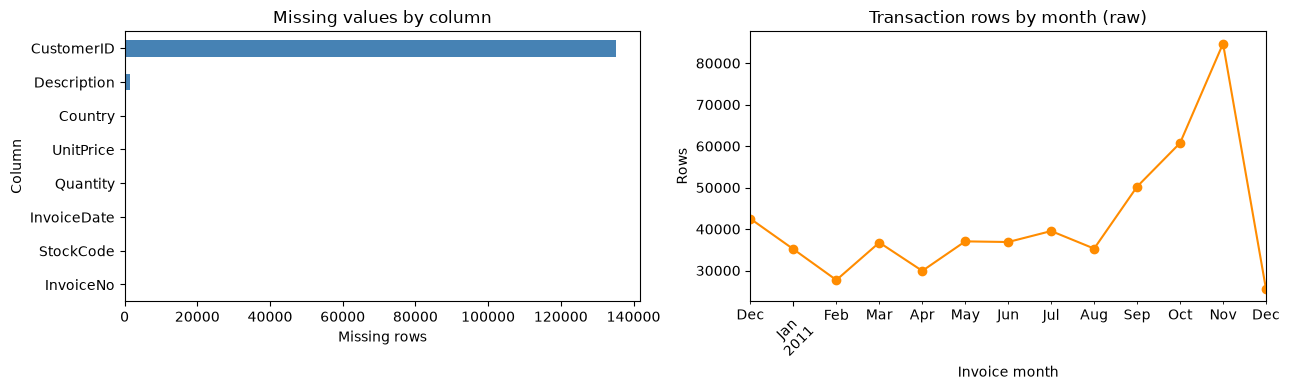

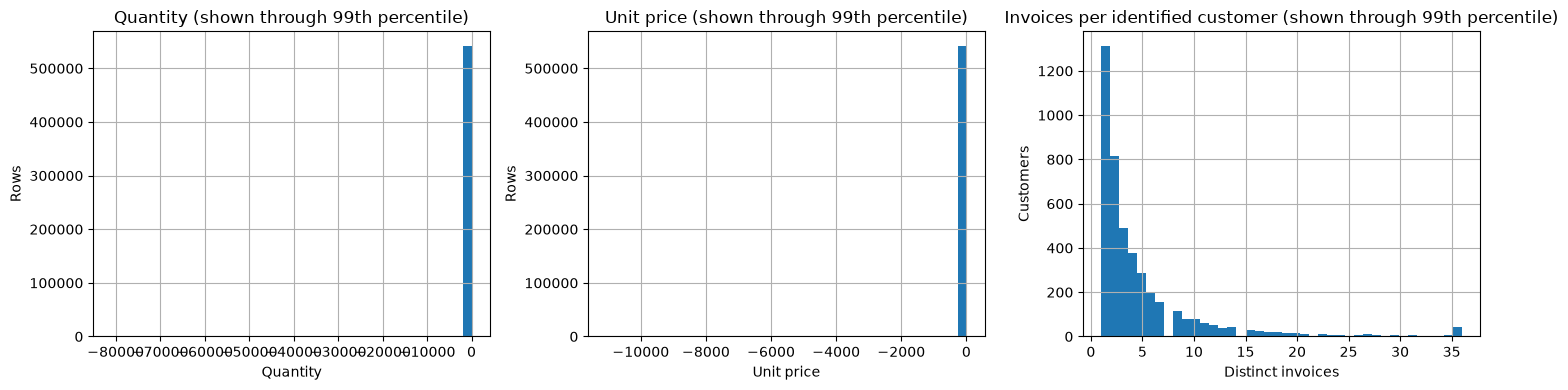

The plots cap only the displayed horizontal range at the 99th percentile; source rows are not removed as outliers.


In [7]:
# Plot raw-data checks honestly: revenue and sales totals below are not yet cleaned.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
missing_table["count"].sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="Missing values by column", xlabel="Missing rows", ylabel="Column")
monthly["transaction_rows"].plot(ax=axes[1], marker="o", color="darkorange")
axes[1].set(title="Transaction rows by month (raw)", xlabel="Invoice month", ylabel="Rows")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(figures_path / "raw_quality_and_monthly_volume.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
exploration["Quantity"].dropna().clip(upper=exploration["Quantity"].quantile(0.99)).hist(bins=40, ax=axes[0])
axes[0].set(title="Quantity (shown through 99th percentile)", xlabel="Quantity", ylabel="Rows")
exploration["UnitPrice"].dropna().clip(upper=exploration["UnitPrice"].quantile(0.99)).hist(bins=40, ax=axes[1])
axes[1].set(title="Unit price (shown through 99th percentile)", xlabel="Unit price", ylabel="Rows")
customer_frequency.clip(upper=customer_frequency.quantile(0.99)).hist(bins=40, ax=axes[2])
axes[2].set(title="Invoices per identified customer (shown through 99th percentile)", xlabel="Distinct invoices", ylabel="Customers")
fig.tight_layout()
fig.savefig(figures_path / "raw_quantity_price_customer_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("The plots cap only the displayed horizontal range at the 99th percentile; source rows are not removed as outliers.")

## Apply reusable preprocessing and reconcile counts

The notebook calls the shared cleaning module rather than reimplementing its algorithm. Sequential exclusions reconcile row losses; diagnostic categories such as cancellation and negative quantity can overlap.

In [8]:
cleaning_result = clean_transactions(transactions)
cleaning_summary = cleaning_result.audit["cleaning"]
print("Sequential row counts:")
display(pd.Series(cleaning_summary["row_counts"], name="rows").to_frame())
print("Positive-purchase exclusion categories (these can overlap):")
display(pd.Series(cleaning_summary["positive_purchase_exclusions"], name="rows").to_frame())

output_paths = write_cleaning_outputs(cleaning_result, processed_path)
print("Generated local outputs:")
for label, output_path in output_paths.items():
    print(f"{label}: {output_path.relative_to(project_root)}")

Sequential row counts:


,rows
input,541909
after_exact_duplicate_removal,536641
after_invalid_date_removal,536641
cleaned_transactions,536641
after_cancellation_exclusion,527390
after_quantity_eligibility,526054
positive_purchase_transactions,524878


Positive-purchase exclusion categories (these can overlap):


,rows
cancellation_invoice_rows,9251
distinct_cancellation_invoices,3836
negative_quantity_rows,10587
zero_quantity_rows,0
missing_quantity_rows,0
negative_unit_price_rows,2
zero_unit_price_rows,2510
missing_unit_price_rows,0
positive_purchase_excluded_unique_rows,11763


Generated local outputs:
cleaned_transactions: data\processed\cleaned_transactions.csv
positive_purchase_transactions: data\processed\positive_purchase_transactions.csv
audit: data\processed\eda_audit.json


## Compare general cleaned transactions with positive purchases

The general output retains valid-date returns and cancellation invoices. The distinct positive-purchase output excludes cancellation-style invoice numbers, nonpositive quantities, and nonpositive unit prices, but retains missing customer or description values for later decisions.

Eligible positive-purchase rows: 524,878
Eligible positive-purchase line revenue: 10,642,110.80
Top countries by eligible positive-purchase line revenue:


,LineRevenue
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


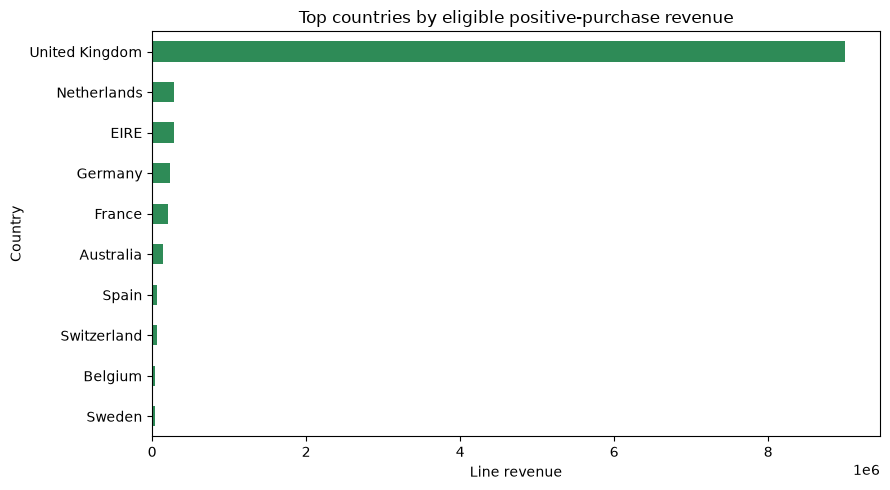

In [9]:
positive = cleaning_result.positive_purchase_transactions
positive = positive.assign(LineRevenue=positive["Quantity"] * positive["UnitPrice"])
print(f"Eligible positive-purchase rows: {len(positive):,}")
print(f"Eligible positive-purchase line revenue: {positive['LineRevenue'].sum():,.2f}")
print("Top countries by eligible positive-purchase line revenue:")
display(positive.groupby("Country")["LineRevenue"].sum().sort_values(ascending=False).head(10).to_frame())

fig, ax = plt.subplots(figsize=(9, 5))
positive.groupby("Country")["LineRevenue"].sum().sort_values().tail(10).plot.barh(ax=ax, color="seagreen")
ax.set(title="Top countries by eligible positive-purchase revenue", xlabel="Line revenue", ylabel="Country")
fig.tight_layout()
fig.savefig(figures_path / "positive_purchase_revenue_by_country.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## Computed findings from this workbook

In [10]:
raw_audit = cleaning_result.audit["before_cleaning"]
cleaning = cleaning_result.audit["cleaning"]
print(f"The source workbook contains {raw_audit['input_row_count']:,} rows and {raw_audit['input_column_count']} columns.")
print(f"Observed invoice dates: {raw_audit['date_coverage']['start']} through {raw_audit['date_coverage']['end']}.")
for column in ("CustomerID", "Description"):
    missing = raw_audit["missing_values"][column]
    print(f"Missing {column}: {missing['count']:,} rows ({missing['percentage']:.2f}%).")
print(f"Exact duplicate rows: {raw_audit['exact_duplicate_row_count']:,}.")
print(f"Cancellation-style invoice rows: {raw_audit['cancellation_invoice_row_count']:,}; negative-quantity rows: {raw_audit['negative_quantity_potential_return_row_count']:,}.")
print(f"After duplicate and date cleaning: {cleaning['row_counts']['cleaned_transactions']:,} transaction rows.")
print(f"Eligible positive-purchase rows: {cleaning['row_counts']['positive_purchase_transactions']:,}.")
print("The cancellation, negative-quantity, and other issue counts can overlap; they are not additive.")

The source workbook contains 541,909 rows and 8 columns.
Observed invoice dates: 2010-12-01T08:26:00 through 2011-12-09T12:50:00.
Missing CustomerID: 135,080 rows (24.93%).
Missing Description: 1,454 rows (0.27%).
Exact duplicate rows: 5,268.
Cancellation-style invoice rows: 9,288; negative-quantity rows: 10,624.
After duplicate and date cleaning: 536,641 transaction rows.
Eligible positive-purchase rows: 524,878.
The cancellation, negative-quantity, and other issue counts can overlap; they are not additive.


## Findings, limitations, and decisions

The cells above compute the observed row/column counts, date coverage, missing values, duplicates, cancellation indicators, quantity/price signs, and positive-purchase totals directly from the local workbook. Review those outputs rather than copying fixed statistics into conclusions.

- Exact duplicate rows are removed from the analytical outputs after their count is recorded.
- Invalid and missing invoice dates are audited and excluded from both cleaned outputs.
- The general cleaned transactions retain cancellation and negative-quantity rows for analysis, and do not drop rows solely for missing customer IDs or descriptions.
- The positive-purchase output excludes cancellation-style invoice numbers and rows without positive quantity and unit price. Its exclusion categories overlap.
- Negative quantities can represent returns or corrections; they are not automatically identified as cancellations.
- Display clipping in histograms improves readability only; no statistical outliers are removed.
- Transaction-level analysis can retain rows without a customer identifier, but those rows cannot directly support customer-level analysis.
- The dataset is observational and its date coverage, returns, missing identifiers, and transaction corrections constrain downstream customer modeling.

**Phase 2 boundary:** This notebook does not choose observation/outcome windows or create customer features, targets, train/test splits, models, clusters, or a UI.